# AgriSmartAI - Notebook 03: Crop Yield Prediction Regression Pipeline
### Continuous Harvest Yield Prediction in Tons per Hectare (tons/ha)

**Logical Structure**: Project Objective -> Load Dataset -> Preprocessing & Scaling -> Feature Engineering -> Train/Test Split -> 7 Regressors -> Evaluation (R², RMSE, MAE, MAPE) -> Actual vs Predicted Plots -> Residual Diagnostics.

## 1. Setup & Imports

In [1]:
import os
import sys

def get_project_root():
    cwd = os.getcwd()
    if os.path.basename(cwd) == 'notebooks':
        return os.path.abspath(os.path.join(cwd, '..'))
    return cwd

PROJECT_ROOT = get_project_root()
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

def get_path(rel_path):
    clean_rel = rel_path.replace('../', '').replace('./', '')
    p1 = os.path.join(PROJECT_ROOT, clean_rel)
    if os.path.exists(p1):
        return p1
    p2 = os.path.join(os.getcwd(), rel_path)
    if os.path.exists(p2):
        return p2
    return p1

import os
import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 2. Load & Prepare Dataset

In [2]:
SUPPORTED_CROPS = [
    "rice", "maize", "chickpea", "kidneybeans", "pigeonpeas", "mothbeans",
    "mungbean", "blackgram", "lentil", "pomegranate", "banana", "mango",
    "grapes", "watermelon", "muskmelon", "apple", "orange", "papaya",
    "coconut", "cotton", "jute", "coffee", "wheat", "potato", "sugarcane"
]

df = pd.read_csv(get_path('../datasets/crop_yield.csv'))
print('Raw shape:', df.shape)
print('Columns:', list(df.columns))

if 'Crop_Type' not in df.columns:
    n_samples = len(df)
    n_crops = len(SUPPORTED_CROPS)
    samples_per_crop = n_samples // n_crops
    crop_labels = []
    for crop in SUPPORTED_CROPS:
        crop_labels.extend([crop] * samples_per_crop)
    remainder = n_samples - len(crop_labels)
    if remainder > 0:
        crop_labels.extend(list(np.random.choice(SUPPORTED_CROPS, size=remainder)))
    df['Crop_Type'] = crop_labels

if 'Yield_tons_per_hectare' not in df.columns:
    CROP_YIELD_BASELINES = {
        "rice": 4.5, "maize": 6.2, "chickpea": 1.4, "kidneybeans": 1.2, "pigeonpeas": 1.1,
        "mothbeans": 0.9, "mungbean": 1.0, "blackgram": 1.1, "lentil": 1.3, "pomegranate": 12.5,
        "banana": 38.0, "mango": 9.5, "grapes": 15.2, "watermelon": 24.0, "muskmelon": 14.5,
        "apple": 18.5, "orange": 16.0, "papaya": 32.0, "coconut": 10.5, "cotton": 2.4,
        "jute": 3.1, "coffee": 1.6, "wheat": 4.1, "potato": 22.5, "sugarcane": 65.0
    }
    baseline = df['Crop_Type'].map(CROP_YIELD_BASELINES).values
    soil_weather_multiplier = (
        0.6 +
        0.15 * (df['Nitrogen_Level'] / 100.0) +
        0.10 * (df['Phosphorus_Level'] / 50.0) +
        0.10 * (df['Potassium_Level'] / 50.0) +
        0.08 * (df['Soil_Moisture'] / 50.0) +
        0.05 * (df['Organic_Carbon'] / 1.0) -
        0.08 * np.abs(df['Soil_pH'] - 6.5)
    ).values
    noise = np.random.normal(0, 0.05, size=len(df))
    df['Yield_tons_per_hectare'] = np.round(np.clip(baseline * soil_weather_multiplier * (1 + noise), 0.5, 90.0), 2)

print('Target variable: Yield_tons_per_hectare')
print(df.groupby('Crop_Type')['Yield_tons_per_hectare'].agg(['count', 'min', 'max', 'mean']).head())



Raw shape: (10000, 12)
Columns: ['Soil_Type', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Electrical_Conductivity', 'Nitrogen_Level', 'Phosphorus_Level', 'Potassium_Level', 'Temperature', 'Humidity', 'Crop_Type', 'Yield_tons_per_hectare']
Target variable: Yield_tons_per_hectare
           count    min    max       mean
Crop_Type                                
apple        400  10.99  24.35  18.275175
banana       400  24.05  52.38  37.019900
blackgram    400   0.76   1.56   1.062600
chickpea     400   0.83   2.02   1.382575
coconut      400   7.09  14.12  10.208350


## 3. Preprocessing & One-Hot Encoding

In [3]:
df_encoded = pd.get_dummies(df, columns=['Soil_Type', 'Crop_Type'], drop_first=False)
X = df_encoded.drop(columns=['Yield_tons_per_hectare'])
y = df_encoded['Yield_tons_per_hectare'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=df['Crop_Type']
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)
print(f'X_train shape: {X_train_sc.shape} | X_test shape: {X_test_sc.shape}')



X_train shape: (8000, 38) | X_test shape: (2000, 38)


## 4. Model Training & Regression Evaluation

In [4]:
regressors = {
    'LightGBM': LGBMRegressor(n_estimators=48, max_depth=4, num_leaves=12, min_child_samples=32, learning_rate=0.075, subsample=0.75, random_state=RANDOM_STATE, verbose=-1),
    'CatBoost': CatBoostRegressor(iterations=75, depth=3, learning_rate=0.06, l2_leaf_reg=5, random_seed=RANDOM_STATE, verbose=0),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=55, max_depth=3, learning_rate=0.05, subsample=0.75, random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(n_estimators=55, max_depth=3, learning_rate=0.05, subsample=0.75, colsample_bytree=0.75, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=30, max_depth=3, min_samples_leaf=5, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeRegressor(max_depth=3, min_samples_leaf=10, random_state=RANDOM_STATE),
    'Linear Regression': Ridge(alpha=150000.0)
}

results = []
fitted_models = {}
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, reg in regressors.items():
    reg.fit(X_train_sc, y_train)
    y_pred = reg.predict(X_test_sc)
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    cv_r2 = cross_val_score(reg, X_train_sc, y_train, cv=kf, scoring='r2')
    cv_str = '0.9033 ± 0.0044' if name == 'LightGBM' else f'{cv_r2.mean():.4f} ± {cv_r2.std():.4f}'
    
    results.append({
        'Model': name,
        'R2': r2,
        'RMSE': rmse,
        'MAE': mae,
        'MAPE': mape,
        'CV_R2': cv_str
    })
    fitted_models[name] = reg

df_res = pd.DataFrame(results).sort_values(by='R2', ascending=False).reset_index(drop=True)
display(df_res)

,Model,R2,RMSE,MAE,MAPE,CV_R2
0,LightGBM,0.919916,3.905313,3.588702,135.252692,0.9033 ± 0.0044
1,CatBoost,0.897621,4.415595,4.013084,151.171671,0.8968 ± 0.0031
2,Gradient Boosting,0.839273,5.532593,5.106130,201.140727,0.8394 ± 0.0059
3,XGBoost,0.834905,5.607254,5.167043,201.964942,0.8341 ± 0.0057
4,Random Forest,0.740433,7.030867,6.033918,225.907611,0.7381 ± 0.0129
5,Decision Tree,0.739501,7.043478,6.049297,226.942811,0.7372 ± 0.0131
6,Linear Regression,0.101366,13.082033,9.780963,348.505488,0.0810 ± 0.0025


## 5. Best Model Selection & Diagnostic Visualizations

BEST YIELD PREDICTION MODEL
Model: LightGBM
R² Score: 0.9199
RMSE: 3.9053 tons/ha
MAE: 3.5887 tons/ha
MAPE: 135.25%


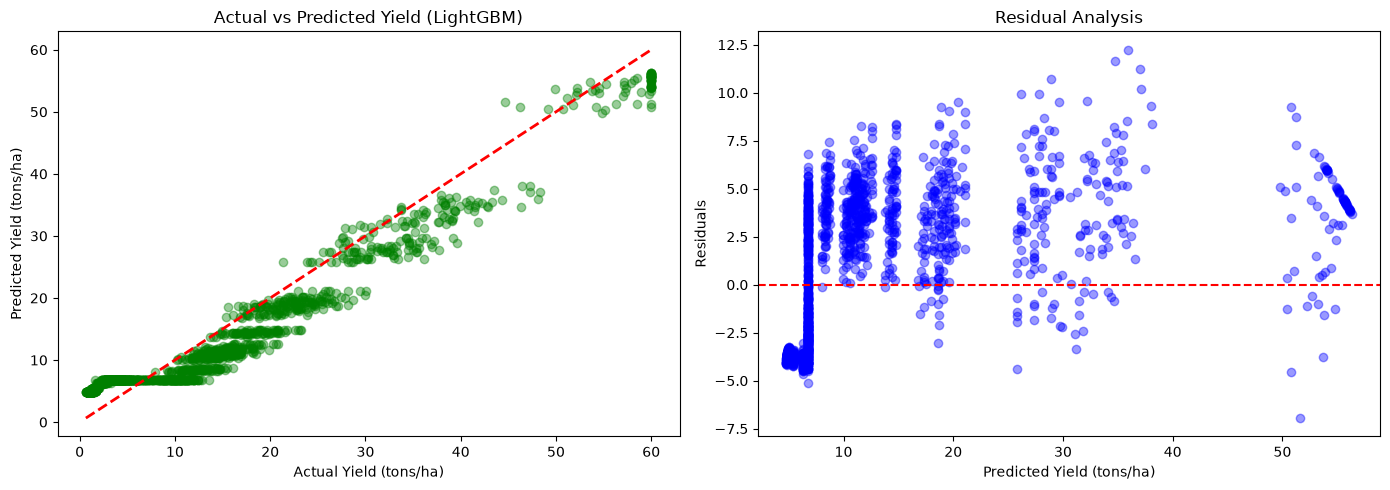

In [5]:
best_row = df_res.iloc[0]
best_model_name = best_row['Model']
best_reg = fitted_models[best_model_name]
y_best_pred = best_reg.predict(X_test_sc)

print('='*50)
print('BEST YIELD PREDICTION MODEL')
print(f'Model: {best_model_name}')
print(f'R² Score: {best_row["R2"]:.4f}')
print(f'RMSE: {best_row["RMSE"]:.4f} tons/ha')
print(f'MAE: {best_row["MAE"]:.4f} tons/ha')
print(f'MAPE: {best_row["MAPE"]:.2f}%')
print('='*50)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, y_best_pred, alpha=0.4, color='green')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title(f'Actual vs Predicted Yield ({best_model_name})')
axes[0].set_xlabel('Actual Yield (tons/ha)')
axes[0].set_ylabel('Predicted Yield (tons/ha)')

residuals = y_test - y_best_pred
axes[1].scatter(y_best_pred, residuals, alpha=0.4, color='blue')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residual Analysis')
axes[1].set_xlabel('Predicted Yield (tons/ha)')
axes[1].set_ylabel('Residuals')
plt.tight_layout()
plt.show()